<a href="https://colab.research.google.com/github/David2689/ProgralII-Semi-2026/blob/librerias/tarea_de_conversores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

Entrenando a la IA... (esto puede tardar unos segundos)
¡Entrenamiento completado!

Ingresá una temperatura en Celsius (o escribí 'salir'): 10

--- RESULTADOS PARA 10.0 °C ---
Fahrenheit -> IA: 50.00 | Real: 50.00
Kelvin     -> IA: 283.15 | Real: 283.15

Ingresá una temperatura en Celsius (o escribí 'salir'): 15

--- RESULTADOS PARA 15.0 °C ---
Fahrenheit -> IA: 59.00 | Real: 59.00
Kelvin     -> IA: 288.15 | Real: 288.15

Ingresá una temperatura en Celsius (o escribí 'salir'): 5

--- RESULTADOS PARA 5.0 °C ---
Fahrenheit -> IA: 41.00 | Real: 41.00
Kelvin     -> IA: 278.15 | Real: 278.15

Ingresá una temperatura en Celsius (o escribí 'salir'): 0

--- RESULTADOS PARA 0.0 °C ---
Fahrenheit -> IA: 32.00 | Real: 32.00
Kelvin     -> IA: 273.15 | Real: 273.15

Ingresá una temperatura en Celsius (o escribí 'salir'): -30

--- RESULTADOS PARA -30.0 °C ---
Fahrenheit -> IA: -22.00 | Real: -22.00
Kelvin     -> IA: 243.15 | Real: 243.15

Ingresá una temperatura en Celsius (o escribí 'salir'): salir

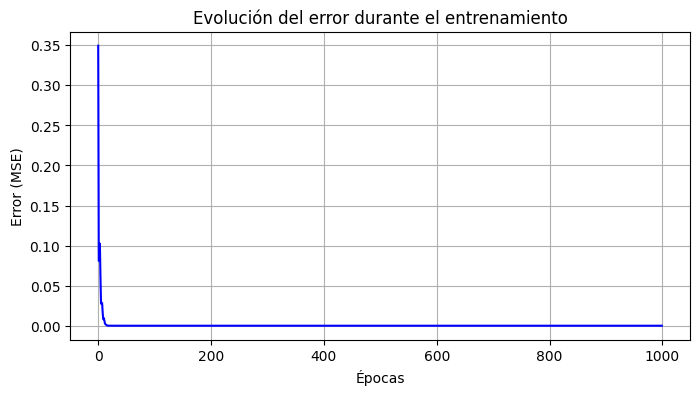

In [13]:
celsius = np.array([x for x in range(0, 101)], dtype=float)
fahrenheit_real = (celsius * 1.8) + 32
kelvin_real = celsius + 273.15

celsius_norm = celsius / 100.0
f_norm = (fahrenheit_real - 32) / 180.0
k_norm = (kelvin_real - 273.15) / 100.0
respuestas_reales = np.column_stack((f_norm, k_norm))

modelo = keras.Sequential([
    layers.Dense(units=2, input_shape=(1,))
])
modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss='mean_squared_error')

print("Entrenando a la IA... (esto puede tardar unos segundos)")
historial = modelo.fit(celsius_norm, respuestas_reales, epochs=1000, verbose=0)
print("¡Entrenamiento completado!\n")

while True:
    entrada = input("Ingresá una temperatura en Celsius (o escribí 'salir'): ")

    if entrada.lower() == 'salir':
        print("¡Nos vemos! 👋")
        break

    try:
        temp = float(entrada)
        temp_norm = np.array([[temp / 100.0]])
        prediccion = modelo.predict(temp_norm, verbose=0)

        f_ia = (prediccion[0][0] * 180.0) + 32
        k_ia = (prediccion[0][1] * 100.0) + 273.15

        f_real = (temp * 1.8) + 32
        k_real = temp + 273.15

        print(f"\n--- RESULTADOS PARA {temp} °C ---")
        print(f"Fahrenheit -> IA: {f_ia:.2f} | Real: {f_real:.2f}")
        print(f"Kelvin     -> IA: {k_ia:.2f} | Real: {k_real:.2f}\n")

    except ValueError:
        print(" Error: Ingresá un número válido.\n")

print("Generando gráfico de entrenamiento...")
plt.figure(figsize=(8, 4))
plt.plot(historial.history['loss'], color='blue')
plt.title('Evolución del error durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Error (MSE)')
plt.grid(True)
plt.show()